In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

import pickle
import os


ModuleNotFoundError: No module named 'pandas'

In [ ]:
### Read CSV
df = pd.read_csv('WineQT.csv')
print('Data shape:', df.shape)
print('Columns:', df.columns.tolist())
df.head()


Data shape: (1143, 13)
Columns: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [ ]:
### Data Information & Missing Values Check
print(df.info())
print(df.describe())
print('Duplicate rows:', df.duplicated().sum())
print('Missing values per column:\n', df.isnull().sum())


<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB
None
       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    1

In [ ]:
### Target Distribution & Feature Selection
print('Quality distribution:')
print(df['quality'].value_counts().sort_index())

# Drop 'Id' (not a predictive feature) and separate features (X) and target (y)
X = df.drop(columns=['quality', 'Id'])
y = df['quality']

print('\nFeatures shape:', X.shape)
print('Target shape:', y.shape)


Quality distribution:
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

Features shape: (1143, 11)
Target shape: (1143,)


In [ ]:
### Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Training set size: {X_train.shape[0]}')
print(f'Testing set size: {X_test.shape[0]}')


Training set size: 914
Testing set size: 229


In [ ]:
### Feature Scaling (StandardScaler)
# KNN is a distance-based algorithm, so feature scaling is essential!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
### Baseline KNN Classifier (k=5)
baseline_knn = KNeighborsClassifier(n_neighbors=5)
baseline_knn.fit(X_train_scaled, y_train)

y_pred_baseline = baseline_knn.predict(X_test_scaled)
print(f'Baseline KNN (k=5) Accuracy: {accuracy_score(y_test, y_pred_baseline):.4f}')


Baseline KNN (k=5) Accuracy: 0.5764


Best k from CV: 18 (Mean CV Accuracy: 0.5689)


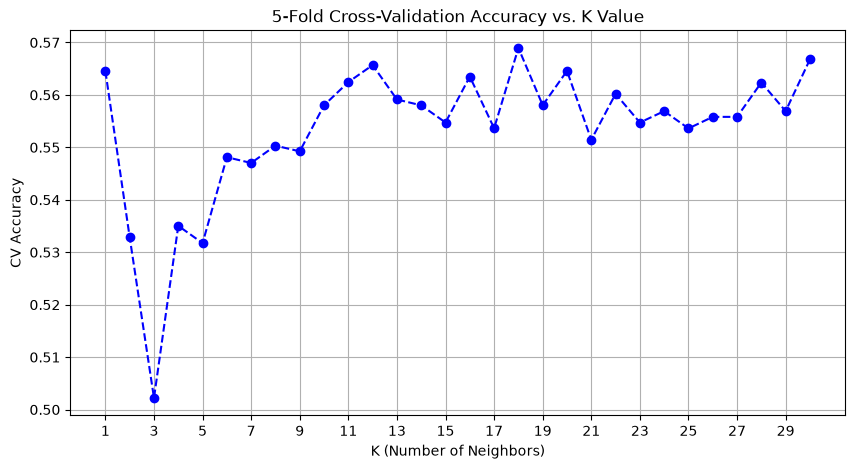

In [ ]:
### Find Optimal K using 5-Fold Cross-Validation
k_range = range(1, 31)
cv_scores = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

best_k = k_range[np.argmax(cv_scores)]
print(f'Best k from CV: {best_k} (Mean CV Accuracy: {max(cv_scores):.4f})')

# Plotting Accuracy vs K
plt.figure(figsize=(10, 5))
plt.plot(k_range, cv_scores, marker='o', linestyle='dashed', color='b')
plt.title('5-Fold Cross-Validation Accuracy vs. K Value')
plt.xlabel('K (Number of Neighbors)')
plt.ylabel('CV Accuracy')
plt.xticks(range(1, 31, 2))
plt.grid(True)
plt.show()


In [ ]:
### Hyperparameter Tuning using GridSearchCV
# Tuning n_neighbors, weights (uniform vs distance), and distance metric (euclidean vs manhattan)
param_grid = {
    'n_neighbors': list(range(1, 31)),
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid.fit(X_train_scaled, y_train)

print('Best Parameters:', grid.best_params_)
print(f'Best Cross-Validation Accuracy: {grid.best_score_:.4f}')


Best Parameters: {'metric': 'euclidean', 'n_neighbors': 24, 'weights': 'distance'}
Best Cross-Validation Accuracy: 0.6433


Test Set Accuracy: 0.6812

Classification Report:
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         7
           5       0.73      0.79      0.76        97
           6       0.64      0.71      0.67        92
           7       0.64      0.48      0.55        29
           8       0.00      0.00      0.00         3

    accuracy                           0.68       229
   macro avg       0.33      0.33      0.33       229
weighted avg       0.65      0.68      0.66       229



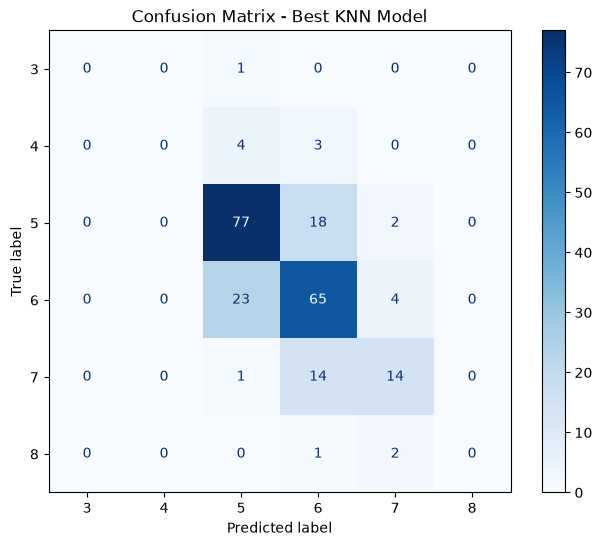

In [ ]:
### Evaluate Final KNN Model on Test Set
best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test_scaled)

print(f'Test Set Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print('\nClassification Report:')
print(classification_report(y_test, y_pred, zero_division=0))

# Confusion Matrix Display
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues', ax=ax)
plt.title('Confusion Matrix - Best KNN Model')
plt.show()


In [ ]:
### Build End-to-End Pipeline & Save Model
# Packaging StandardScaler and the best KNN together ensures future raw inputs are scaled correctly
final_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', best_knn)
])
final_pipeline.fit(X_train, y_train)

model_filename = 'final_knn_model.pkl'
with open(model_filename, 'wb') as file:
    pickle.dump(final_pipeline, file)

print(f"Model pipeline saved successfully to '{model_filename}'")


Model pipeline saved successfully to 'final_knn_model.pkl'


In [ ]:
### Load and Verify Saved Model
with open(model_filename, 'rb') as file:
    loaded_model = pickle.load(file)

print('Model loaded successfully!')
print('Model file exists:', os.path.exists(model_filename))

# Check predictions match
sample_preds_orig = final_pipeline.predict(X_test[:10])
sample_preds_load = loaded_model.predict(X_test[:10])

print('Original Pipeline Predictions:', sample_preds_orig)
print('Loaded Model Predictions:    ', sample_preds_load)
print('Do predictions match?:', np.array_equal(sample_preds_orig, sample_preds_load))


Model loaded successfully!
Model file exists: True


Original Pipeline Predictions: [6 5 5 5 6 6 6 7 6 5]
Loaded Model Predictions:     [6 5 5 5 6 6 6 7 6 5]
Do predictions match?: True
